# Tutorial 0 — Definição das superfícies


## 1. Importações


In [1]:
from pathlib import Path
import sys

# Importar o pacote local
project_root = Path.cwd()
if project_root.name == "tutorials":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt

from meshlab.core import Mesh, Curve, Contour
from meshlab.operations import insert_contour
from meshlab.utils import plot_mesh

## 2. Círculo


In [2]:
center = np.array([-1.8, 0.0])
radius = 0.8
num_circle_points = 64

# Sentido anti-horário
angles = np.linspace(0.0, 2.0 * np.pi, num_circle_points, endpoint=False)
circle_points = center + radius * np.column_stack((np.cos(angles), np.sin(angles)))
# Fechar a curva
circle_points = np.vstack((circle_points, circle_points[0]))

circle = Contour("circle_body", [Curve("circle", circle_points)])

## 3. Quadrado


In [3]:
# Vértices em sentido anti-horário
corners = np.array([
    [0.8, -0.8],
    [2.4, -0.8],
    [2.4,  0.8],
    [0.8,  0.8],
])
points_per_side = 12

square_points = np.vstack([
    np.linspace(start, end, points_per_side, endpoint=False)
    for start, end in zip(corners, np.roll(corners, -1, axis=0))
])
square_points = np.vstack((square_points, square_points[0]))

square = Contour("square_body", [Curve("square", square_points)])

## 4. Domínio retangular


In [4]:
xmin, xmax = -5.0, 5.0
ymin, ymax = -3.0, 3.0

# Contorno externo em sentido horário
inlet = Curve("inlet", np.linspace([xmin, ymin], [xmin, ymax], 17))
laterals_upper = Curve("laterals_upper", np.linspace([xmin, ymax], [xmax, ymax], 41))
outlet = Curve("outlet", np.linspace([xmax, ymax], [xmax, ymin], 17))
laterals_lower = Curve("laterals_lower", np.linspace([xmax, ymin], [xmin, ymin], 41))

domain = Contour("outer_domain", [inlet, laterals_upper, outlet, laterals_lower])

## 5. Inserção na malha


In [5]:
mesh = Mesh(dim=2)

insert_contour(mesh, domain)
insert_contour(mesh, circle)
insert_contour(mesh, square)

## 6. Visualização


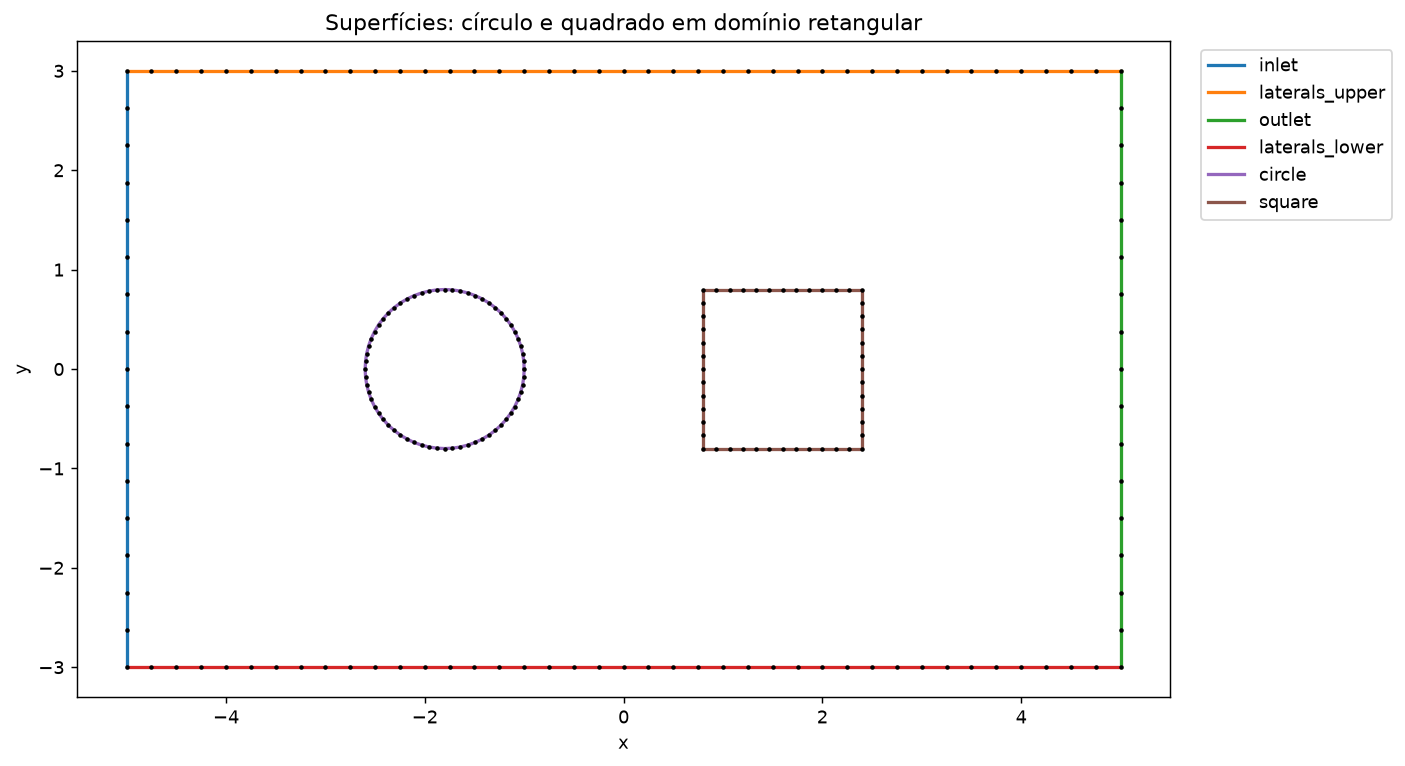

In [6]:
figure, ax = plot_mesh(mesh, show=False)
figure.set_size_inches(11, 6)
ax.set_title("Superfícies: círculo e quadrado em domínio retangular")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
figure.tight_layout()
plt.show()